# Why might a spatial code look like a grid?
### Dorrell et al. (2023): an independent reproduction using NeuralPlayground
**Nathan Le Roux and Tafara Chibanda — Wits Computational Neuroscience, 2026**

Grid cells respond at multiple locations that can form a hexagonal pattern.
Dorrell and colleagues ask whether a useful, movement-compatible representation
of position can explain such patterns. We implemented part of their model
independently and found that its numerical settings strongly affect the outcome.

This notebook uses **NeuralPlayground's Simple2D arena** to explore a learned
representation. It also runs a short optimisation demonstration and examines
three saved, full-length course-project runs. It adds no standalone library agent.

**Run all cells in order.** The default execution is a short demonstration, not
150,000-step retraining. Saved results are explicitly labelled and embedded in
this file, so there are no companion files or dataset downloads. Runtime depends
on the CPU; the training budget is adjustable below.

Install NeuralPlayground from your fork with `python -m pip install -e .`, then
open this notebook in Jupyter using that environment. NumPy, pandas and Matplotlib
are included among the library's dependencies. Tested against upstream commit
`f72e6c0896d0b343cc884ba700f44e0e29122f1f`.

Paper: [Dorrell et al., Actionable Neural Representations: Grid Cells from Minimal
Constraints, ICLR 2023](https://arxiv.org/abs/2209.15563).

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('jpeg')

import base64
import hashlib
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from neuralplayground.arenas import Simple2D

plt.rcParams.update({"figure.dpi": 80, "font.size": 10})

## 1. A representation that can be moved

The model converts a position $x=(x_1,x_2)$ into one activity value per neuron:

$$g(x)=a_0+\sum_d A_d\sin(k_d\cdot x)+B_d\cos(k_d\cdot x).$$

The learned vectors $k_d$ control the spatial waves; $A_d$, $B_d$ and $a_0$
combine them into the population response. For a full-rank coefficient matrix,
a movement can update this response through a position-independent linear
transformation. Hexagonal geometry is not explicitly imposed by this formula.

Training balances three quantities:

1. **Discrimination:** different locations should have different population codes.
2. **Non-negativity:** negative activity receives a penalty.
3. **Boundedness:** normalised energy should change little across shifted rooms.

The following cell contains the NumPy equations and analytic gradients from our
independent reproduction. `TrainConfig` makes the numerical conventions explicit.
It is included here to keep the example self-contained; readers can run it and
continue to the plots without studying each derivative.

In [2]:
"""Fourier model, analytic loss gradients and optimiser components.

Everything is implemented from the paper's Section 2/3 and Appendix B.1 ("very large
spaces").  No autodiff library is used (so the only dependency is NumPy); the analytic
gradients are verified against finite differences in the checks below and our project tests.

Model  (paper eq. 6 / 20):   g(x) = a0 + sum_d  a_d sin(k_d . x) + b_d cos(k_d . x)
    a0 in R^N, a_d, b_d in R^N, k_d in R^dim  (frequencies k_d are *learned*).
The number of frequencies D must be < N/2 for the code to be actionable (App. A).
"""

# Adapted from Nathan Le Roux and Tafara Chibanda's independent reproduction.
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, Tuple

import numpy as np

Params = Dict[str, np.ndarray]  # keys: a0 (N,), A (D,N), B (D,N), K (D,dim)


# --------------------------------------------------------------------------- model
def init_params(
    N: int,
    D: int,
    dim: int,
    rng: np.random.Generator,
    coef_std: float = 1.0,
    freq_std: float = 4.0,
    dtype="float64",
) -> Params:
    """Zero-mean Gaussian init (paper: 'independent zero-mean gaussians'; the variances
    are NOT given in the paper's table B.3, so they are hyper-parameters here).
    """
    p = {
        "a0": rng.normal(0, coef_std, N) / np.sqrt(D),
        "A": rng.normal(0, coef_std, (D, N)) / np.sqrt(D),
        "B": rng.normal(0, coef_std, (D, N)) / np.sqrt(D),
        "K": rng.normal(0, freq_std, (D, dim)),
    }
    return {k: v.astype(dtype) for k, v in p.items()}


def encode(p: Params, X: np.ndarray, cache: bool = False):
    """g(X) for X of shape (P, dim) -> (P, N)."""
    Phi = X @ p["K"].T
    S, C = np.sin(Phi), np.cos(Phi)
    G = p["a0"] + S @ p["A"] + C @ p["B"]
    return (G, (S, C)) if cache else G


def _backprop_to_params(
    p: Params,
    X: np.ndarray,
    S: np.ndarray,
    C: np.ndarray,
    dG: np.ndarray,
    grads: Params,
) -> None:
    """Accumulate d loss / d params given d loss / d G at positions X."""
    grads["a0"] += dG.sum(0)
    grads["A"] += S.T @ dG
    grads["B"] += C.T @ dG
    dPhi = (dG @ p["A"].T) * C - (dG @ p["B"].T) * S  # (P, D)
    grads["K"] += dPhi.T @ X


# --------------------------------------------------------------------------- losses
def functional_loss(
    Gt: np.ndarray,
    X: np.ndarray,
    sigma: float,
    spatial_scale: float,
    kind: str = "full",
) -> Tuple[float, np.ndarray]:
    """Discrete version of eq. 1/23.

    Gt = normalised code (M, N), X = positions (M, dim).
    kind='full': mean_ij exp(-|g_i-g_j|^2 / 2 sigma^2) chi(x_i,x_j)
    kind='l0'  : -mean_ij |g_i - g_j|^2        (simplified loss of eq. 7)
    Returns (loss, dloss/dGt).
    """
    M = Gt.shape[0]
    sq = (Gt**2).sum(1)
    D2 = np.maximum(sq[:, None] + sq[None, :] - 2.0 * Gt @ Gt.T, 0.0)
    if kind == "l0":
        L = -D2.mean()
        grad = -(4.0 / M) * (Gt - Gt.mean(0))
        return float(L), grad
    sx = (X**2).sum(1)
    DX2 = np.maximum(sx[:, None] + sx[None, :] - 2.0 * X @ X.T, 0.0)
    chi = 1.0 - np.exp(-DX2 / (2.0 * spatial_scale**2))
    W = np.exp(-D2 / (2.0 * sigma**2)) * chi
    L = W.mean()
    # dL/dGt_i = -(2 / (sigma^2 M^2)) sum_j W_ij (Gt_i - Gt_j)
    grad = -(2.0 / (sigma**2 * M**2)) * (W.sum(1)[:, None] * Gt - W @ Gt)
    return float(L), grad


@dataclass
class TrainConfig:
    """Numerical conventions of the independent NumPy reproduction.

    See this notebook's numerical conventions section.
    """

    # --- problem (paper Table B.3 defaults for Fig. 2B)
    N: int = 64
    D: int = 31  # number of frequencies (< N/2); NOT stated in the paper
    dim: int = 2
    sigma: float = 0.2  # neural length-scale
    l: float = 0.5  # noqa: E741 - retain the paper and reproduction notation
    L: float = 1.0  # occupancy length-scale (units of space)
    occupancy: str = "gaussian"  # Gaussian or uniform with variance L^2 per axis
    functional: str = "full"  # 'full' | 'l0' | 'none'
    norm_mode: str = (
        "sum"  # 'sum': unit L2 norm over the M samples (eq. 22 read literally)
    )
    # 'mean': unit mean-square (the continuous constraint of eq. 2)
    # --- optimisation
    steps: int = 150_000
    M: int = 150  # sampled points
    MS: int = 15  # sampled room shifts
    S: float = 3.0  # std of shift sampling
    n_resample: int = 5
    lr_coef: float = 0.1
    lr_freq: float = 0.1
    beta1: float = 0.9
    beta2: float = 0.9
    eps: float = 1e-8
    lr_decay_to: float = (
        1.0  # final lr = lr * lr_decay_to (1.0 = constant, as in the paper)
    )
    # --- GECO (positivity p, norm n)
    lam_p0: float = 0.1
    k_p: float = -9.0
    alpha_p: float = 0.9
    gamma_p: float = 1e-4
    lam_n0: float = 0.005
    k_n: float = 4.0
    alpha_n: float = 0.9
    gamma_n: float = 1e-4
    use_positivity: bool = True
    use_norm: bool = True
    # --- init
    coef_std: float = 1.0
    freq_std: float = 4.0
    seed: int = 0
    log_every: int = 500
    dtype: str = "float32"  # float64 is used in the gradient tests


def sample_points(cfg: TrainConfig, rng: np.random.Generator):
    if cfg.occupancy == "uniform":  # same variance L^2 as the Gaussian
        X = rng.uniform(-np.sqrt(3.0) * cfg.L, np.sqrt(3.0) * cfg.L, (cfg.M, cfg.dim))
    else:
        X = rng.normal(0.0, cfg.L, (cfg.M, cfg.dim))  # x ~ p(x) = N(0, L^2 I)
    shifts = rng.normal(0.0, cfg.S, (cfg.MS, cfg.dim))  # 'room shifts'
    return X.astype(cfg.dtype), shifts.astype(cfg.dtype)


def loss_and_grads(
    p: Params,
    X: np.ndarray,
    shifts: np.ndarray,
    cfg: TrainConfig,
    lam_p: float,
    lam_n: float,
    want_grad: bool = True,
):
    """Full loss L = L_func + lam_p L_nonneg + lam_n L_bounded (eq. 21, 23-25).

    Interpretation choices (see the accompanying model documentation):
      * 'sum': normalise each neuron by its sampled L2 norm (equation 22).
      * 'mean': divide the sampled squared norm by M before taking its root.
      * Use the same normaliser for the shifted copies of the room.
      * Boundedness penalises squared deviations of shifted normalised energy
        from one, using sums or means consistently with norm_mode.
    """
    M, MS, N, dim = cfg.M, cfg.MS, cfg.N, cfg.dim
    G, (S0, C0) = encode(p, X, cache=True)
    c = 1.0 if cfg.norm_mode == "sum" else 1.0 / M
    s = np.sqrt(c * (G**2).sum(0)) + 1e-12  # (N,)
    Gt = G / s

    if cfg.functional == "none":
        Lf, dGt = 0.0, np.zeros_like(Gt)
    else:
        Lf, dGt = functional_loss(Gt, X, cfg.sigma, cfg.l, cfg.functional)

    # shifted rooms
    Xs = (X[None, :, :] + shifts[:, None, :]).reshape(MS * M, dim)
    H, (S1, C1) = encode(p, Xs, cache=True)
    Ht = (H / s).reshape(MS, M, N)
    neg = Ht < 0
    Lp = float(np.where(neg, -Ht, 0.0).mean())
    q = c * (Ht**2).sum(1)  # (MS, N)
    Lb = float(((q - 1.0) ** 2).mean())
    out = {"Lf": Lf, "Lp": Lp, "Lb": Lb}
    if not want_grad:
        return out, None

    wp = lam_p if cfg.use_positivity else 0.0
    wn = lam_n if cfg.use_norm else 0.0
    dHt = np.zeros_like(Ht)
    if wp:
        dHt += wp * (-neg.astype(float)) / Ht.size
    if wn:
        dHt += wn * (2.0 * (q - 1.0) / (MS * N))[:, None, :] * (2.0 * c * Ht)
    dHt = dHt.reshape(MS * M, N)
    # back through normalisation  g~ = g / s   (s depends on G)
    dG = dGt / s
    dH = dHt / s
    ds = -((dGt * G).sum(0) + (dHt * H).sum(0)) / s**2
    dG = dG + ds * c * G / s
    grads = {k: np.zeros_like(v) for k, v in p.items()}
    _backprop_to_params(p, X, S0, C0, dG, grads)
    _backprop_to_params(p, Xs, S1, C1, dH, grads)
    return out, grads


# --------------------------------------------------------------------------- optimiser
class Adam:
    def __init__(self, params: Params, lrs: Dict[str, float], b1=0.9, b2=0.9, eps=1e-8):
        self.lrs, self.b1, self.b2, self.eps, self.t = dict(lrs), b1, b2, eps, 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, params: Params, grads: Params, lr_scale: float = 1.0):
        self.t += 1
        c1, c2 = 1 - self.b1**self.t, 1 - self.b2**self.t
        for k in params:
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * grads[k]
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * grads[k] ** 2
            params[k] -= (
                lr_scale
                * self.lrs[k]
                * (self.m[k] / c1)
                / (np.sqrt(self.v[k] / c2) + self.eps)
            )


class GECO:
    """Rezende & Viola (2018)-style constraint weighting, paper eqs. 26-28.
    log-violation  l_t = log(L_t) - k ;  smoothed lhat = a lhat + (1-a) l_t ;
    lambda <- lambda * exp(gamma * lhat).
    """

    def __init__(self, lam0: float, k: float, alpha: float, gamma: float):
        self.lam, self.k, self.alpha, self.gamma, self.lhat = lam0, k, alpha, gamma, 0.0

    def update(self, L: float) -> float:
        lt = np.log(max(L, 1e-30)) - self.k
        self.lhat = self.alpha * self.lhat + (1 - self.alpha) * lt
        self.lam = float(np.clip(self.lam * np.exp(self.gamma * self.lhat), 1e-8, 1e8))
        return self.lam

## 2. Run a short training demonstration

`DEMO_STEPS = 100` checks that the model learns and produces finite losses; it is
too short to assess grid formation. Set it to `150_000` to run the full budget.
The seed controls initialisation and sampled positions. Training uses independent
Gaussian position samples, **not the arena trajectory**. The optimiser is not a
proposed local biological learning rule.

We use sigma=1.0 here because it produced positive geometry examples in our
project. It is an exploratory reproduction setting, not a claim about the
paper's default. Losses below are measured before each parameter update.

Fresh demonstration: 100 updates in 0.4s

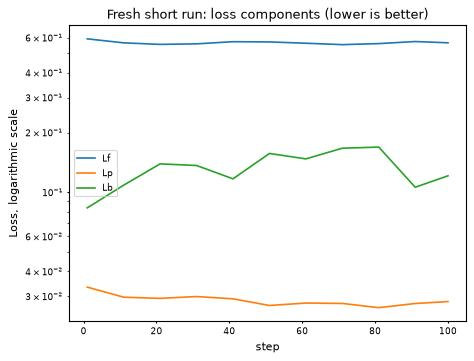

In [3]:
def train_example(cfg):
    if cfg.steps < 1:
        raise ValueError("Use at least one training step.")
    rng = np.random.default_rng(cfg.seed)
    params = init_params(cfg.N, cfg.D, cfg.dim, rng,
                         cfg.coef_std, cfg.freq_std, cfg.dtype)
    opt = Adam(params, {"a0": cfg.lr_coef, "A": cfg.lr_coef,
                       "B": cfg.lr_coef, "K": cfg.lr_freq},
               cfg.beta1, cfg.beta2, cfg.eps)
    gp = GECO(cfg.lam_p0, cfg.k_p, cfg.alpha_p, cfg.gamma_p)
    gn = GECO(cfg.lam_n0, cfg.k_n, cfg.alpha_n, cfg.gamma_n)
    history = []
    for step in range(cfg.steps):
        if step % cfg.n_resample == 0:
            x, shifts = sample_points(cfg, rng)
        losses, grads = loss_and_grads(params, x, shifts, cfg, gp.lam, gn.lam)
        if not all(np.isfinite(v) for v in losses.values()):
            raise FloatingPointError("Non-finite training loss")
        if not all(np.isfinite(v).all() for v in grads.values()):
            raise FloatingPointError("Non-finite gradient")
        if cfg.use_positivity:
            gp.update(losses["Lp"])
        if cfg.use_norm:
            gn.update(losses["Lb"])
        scale = 1 + (cfg.lr_decay_to - 1) * step / max(cfg.steps - 1, 1)
        opt.step(params, grads, scale)
        if step % cfg.log_every == 0 or step == cfg.steps - 1:
            history.append(dict(step=step + 1, **losses))
    return params, pd.DataFrame(history)


DEMO_STEPS = 100
demo_config = TrainConfig(steps=DEMO_STEPS, sigma=1.0, seed=0, log_every=10)
started = time.perf_counter()
demo_params, demo_history = train_example(demo_config)
print(f"Fresh demonstration: {DEMO_STEPS} updates in {time.perf_counter()-started:.1f}s")
ax = demo_history.plot(x="step", y=["Lf", "Lp", "Lb"], logy=True,
                       title="Fresh short run: loss components (lower is better)")
ax.set_ylabel("Loss, logarithmic scale")
plt.show()

## 3. Inspect saved full-length results

The next cell contains three small parameter archives from our submitted NumPy
experiments: sigma=1.0 with seeds 0 and 1, and sigma=0.2 with seed 0. Each was
trained for **150,000 updates**. These are saved results, not generated by the
short run above. We include two positive geometry examples and a contrasting
setting; this small selection is not an estimate of success probability.

The encoded bytes keep this submission to one notebook. Each archive is checked
against its SHA-256 digest and loaded without pickle. The original run name,
configuration and digest are retained for provenance. No experimental animal
data or paper-author code is bundled.

In [4]:
SAVED_RUNS = {'main_sigma1.0_seed0': {'config': {'N': 64, 'D': 31, 'dim': 2, 'sigma': 1.0, 'l': 0.5, 'L': 1.0, 'occupancy': 'gaussian', 'functional': 'full', 'norm_mode': 'sum', 'steps': 150000, 'M': 150, 'MS': 15, 'S': 3.0, 'n_resample': 5, 'lr_coef': 0.1, 'lr_freq': 0.1, 'beta1': 0.9, 'beta2': 0.9, 'eps': 1e-08, 'lr_decay_to': 1.0, 'lam_p0': 0.1, 'k_p': -9.0, 'alpha_p': 0.9, 'gamma_p': 0.0001, 'lam_n0': 0.005, 'k_n': 4.0, 'alpha_n': 0.9, 'gamma_n': 0.0001, 'use_positivity': True, 'use_norm': True, 'coef_std': 1.0, 'freq_std': 4.0, 'seed': 0, 'log_every': 500, 'dtype': 'float32'}, 'sha256': 'fff574abde25bbb911294afa010b578a88ce1dbfa11760a38901302a600d6360', 'archive': '...'}, 'main_sigma1.0_seed1': {'config': {'N': 64, 'D': 31, 'dim': 2, 'sigma': 1.0, 'l': 0.5, 'L': 1.0, 'occupancy': 'gaussian', 'functional': 'full', 'norm_mode': 'sum', 'steps': 150000, 'M': 150, 'MS': 15, 'S': 3.0, 'n_resample': 5, 'lr_coef': 0.1, 'lr_freq': 0.1, 'beta1': 0.9, 'beta2': 0.9, 'eps': 1e-08, 'lr_decay_to': 1.0, 'lam_p0': 0.1, 'k_p': -9.0, 'alpha_p': 0.9, 'gamma_p': 0.0001, 'lam_n0': 0.005, 'k_n': 4.0, 'alpha_n': 0.9, 'gamma_n': 0.0001, 'use_positivity': True, 'use_norm': True, 'coef_std': 1.0, 'freq_std': 4.0, 'seed': 1, 'log_every': 500, 'dtype': 'float32'}, 'sha256': '8465b47590a7c736de02063e0c56c4b96355beba142bda38694f0f3ddf343b64', 'archive': '...'}, 'main_sigma0.2_seed0': {'config': {'N': 64, 'D': 31, 'dim': 2, 'sigma': 0.2, 'l': 0.5, 'L': 1.0, 'occupancy': 'gaussian', 'functional': 'full', 'norm_mode': 'sum', 'steps': 150000, 'M': 150, 'MS': 15, 'S': 3.0, 'n_resample': 5, 'lr_coef': 0.1, 'lr_freq': 0.1, 'beta1': 0.9, 'beta2': 0.9, 'eps': 1e-08, 'lr_decay_to': 1.0, 'lam_p0': 0.1, 'k_p': -9.0, 'alpha_p': 0.9, 'gamma_p': 0.0001, 'lam_n0': 0.005, 'k_n': 4.0, 'alpha_n': 0.9, 'gamma_n': 0.0001, 'use_positivity': True, 'use_norm': True, 'coef_std': 1.0, 'freq_std': 4.0, 'seed': 0, 'log_every': 500, 'dtype': 'float32'}, 'sha256': '7562113acd1249cd236c82f56ce1b6c98b7e7d903e55d22e1f8ea8729013b464', 'archive': '...'}}

saved_params = {}
for name, record in SAVED_RUNS.items():
    raw = base64.b64decode(record['archive'], validate=True)
    assert hashlib.sha256(raw).hexdigest() == record['sha256']
    with np.load(io.BytesIO(raw), allow_pickle=False) as archive:
        saved_params[name] = {key: archive[key].copy() for key in ('a0', 'A', 'B', 'K')}
display(pd.DataFrame([dict(run=name, steps=r['config']['steps'], sigma=r['config']['sigma'], seed=r['config']['seed'], sha256=r['sha256']) for name, r in SAVED_RUNS.items()]))

,run,steps,sigma,seed,sha256
0,main_sigma1.0_seed0,150000,1.0,0,fff574abde25bbb911294afa010b578a88ce1dbfa11760...
1,main_sigma1.0_seed1,150000,1.0,1,8465b47590a7c736de02063e0c56c4b96355beba142bda...
2,main_sigma0.2_seed0,150000,0.2,0,7562113acd1249cd236c82f56ce1b6c98b7e7d903e55d2...


### Spatial activity maps

We show cells 0, 1 and 2 by fixed index, without choosing the best-looking cells.
The window is larger than the training occupancy scale so that broad patterns
can be seen. Sampling resolution adapts to the largest learned frequency to
avoid aliasing. Colours show **raw activity**; negative values are retained.
Colour scales differ across panels, so compare geometry rather than brightness.
These maps illustrate structure; they are not a statistical grid-cell test.

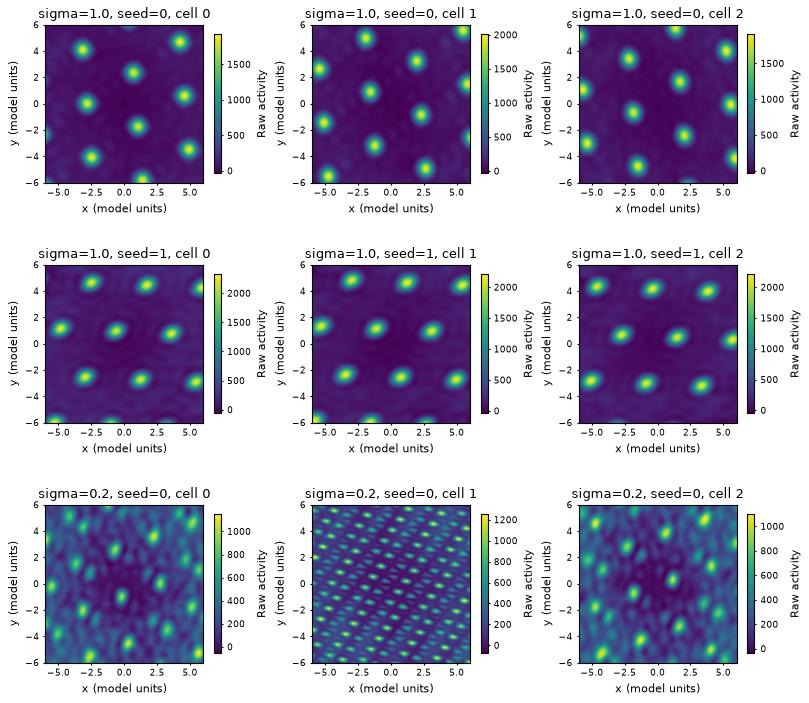

In [5]:
def selected_maps(params, cells=(0, 1, 2), half_width=6.0):
    max_frequency = float(np.abs(params["K"]).max())
    resolution = max(256, int(np.ceil(2 * half_width * max_frequency * 1.25 / np.pi)) + 1)
    if resolution > 4096:
        raise ValueError("Choose a smaller viewing window for these high frequencies.")
    axis = np.linspace(-half_width, half_width, resolution)
    assert max_frequency * (axis[1] - axis[0]) < np.pi
    maps = np.empty((resolution, resolution, len(cells)))
    # Evaluate strips to bound memory, including for high learned frequencies.
    for first in range(0, resolution, 16):
        xx, yy = np.meshgrid(axis, axis[first:first+16])
        positions = np.column_stack((xx.ravel(), yy.ravel()))
        phase = positions @ params["K"].T
        rates = (params["a0"][list(cells)]
                 + np.sin(phase) @ params["A"][:, cells]
                 + np.cos(phase) @ params["B"][:, cells])
        maps[first:first+16] = rates.reshape(len(yy), resolution, len(cells))
    return maps


fig, axes = plt.subplots(3, 3, figsize=(10, 9), layout="constrained")
for row, (name, params) in enumerate(saved_params.items()):
    maps = selected_maps(params)
    for cell in range(3):
        ax = axes[row, cell]
        im = ax.imshow(maps[:, :, cell], origin="lower", extent=(-6, 6, -6, 6))
        ax.set_title(f"sigma={SAVED_RUNS[name]['config']['sigma']}, "
                     f"seed={SAVED_RUNS[name]['config']['seed']}, cell {cell}")
        ax.set(xlabel="x (model units)", ylabel="y (model units)")
        fig.colorbar(im, ax=ax, shrink=0.65, label="Raw activity")
plt.show()

## 4. Explore the learned code in NeuralPlayground

`Simple2D` supplies the arena, position observations and wall interactions. A
seeded random walk supplies proposed displacements. We evaluate the saved model
at the **actual returned position**, since walls can change a proposed movement.
Model positions and arena coordinates share the same units; there is no hidden
conversion to centimetres. This stage is inference only: weights stay fixed.

The coloured path shows how one neuron's response changes as the simulated animal
moves. Sparse trajectory coverage should not be mistaken for a full rate map.

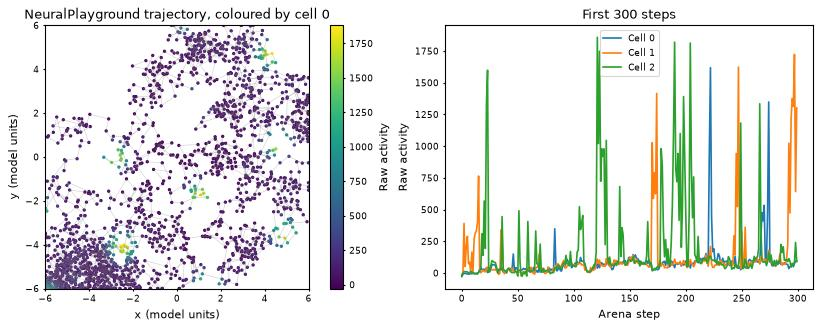

In [6]:
chosen_name = "main_sigma1.0_seed0"
chosen = saved_params[chosen_name]
arena = Simple2D(arena_x_limits=(-6, 6), arena_y_limits=(-6, 6))
obs, _ = arena.reset(custom_state=np.array([0.0, 0.0]))
walk_rng = np.random.default_rng(2026)
positions = [np.asarray(obs[:2]).copy()]
for _ in range(2000):
    obs, _, _ = arena.step(walk_rng.normal(scale=0.35, size=2))
    positions.append(np.asarray(obs[:2]).copy())
positions = np.array(positions)
assert np.isfinite(positions).all() and np.abs(positions).max() <= 6 + 1e-8
activity = encode(chosen, positions)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(*positions.T, color="grey", linewidth=0.5, alpha=0.4)
points = axes[0].scatter(*positions.T, c=activity[:, 0], s=4)
axes[0].set(xlim=(-6, 6), ylim=(-6, 6), aspect="equal",
            xlabel="x (model units)", ylabel="y (model units)",
            title="NeuralPlayground trajectory, coloured by cell 0")
fig.colorbar(points, ax=axes[0], label="Raw activity")
axes[1].plot(activity[:300, :3])
axes[1].set(xlabel="Arena step", ylabel="Raw activity", title="First 300 steps")
axes[1].legend(["Cell 0", "Cell 1", "Cell 2"])
plt.show()

## 5. Check the science separately from the pictures

We evaluate each saved model on eight fresh batches, using the same held-out
sampling seed across runs. The negative-activity and shifted-room norm penalties
are compared with the configured targets. A low average negativity penalty does
not guarantee every response is non-negative, so we also report the fraction of
negative sampled responses. These batches measure sampling variation, not
independent training replications.

In [7]:
rows = []
for name, params in saved_params.items():
    cfg = TrainConfig(**SAVED_RUNS[name]["config"])
    rng = np.random.default_rng(12345)
    losses, negative_fractions = [], []
    for _ in range(8):
        x, shifts = sample_points(cfg, rng)
        result, _ = loss_and_grads(params, x, shifts, cfg, 0, 0, want_grad=False)
        losses.append(result)
        responses = encode(params, (x[None, :, :] + shifts[:, None, :]).reshape(-1, 2))
        negative_fractions.append(float(np.mean(responses < 0)))
    means = {key: float(np.mean([r[key] for r in losses])) for key in losses[0]}
    rows.append(dict(run=name, **means, negative_fraction=np.mean(negative_fractions),
                     positivity_target=np.exp(cfg.k_p), norm_target=np.exp(cfg.k_n),
                     positivity_pass=means["Lp"] <= np.exp(cfg.k_p),
                     norm_pass=means["Lb"] <= np.exp(cfg.k_n)))
held_out = pd.DataFrame(rows)
display(held_out)
assert np.isfinite(held_out[["Lf", "Lp", "Lb", "negative_fraction"]]).all().all()

,run,Lf,Lp,Lb,negative_fraction,positivity_target,norm_target,positivity_pass,norm_pass
0,main_sigma1.0_seed0,0.593852,0.000221,1.813822,0.080726,0.000123,54.59815,False,True
1,main_sigma1.0_seed1,0.599172,0.000118,2.045649,0.044305,0.000123,54.59815,True,True
2,main_sigma0.2_seed0,0.000623,0.000220,4.842532,0.048793,0.000123,54.59815,False,True


### Two implementation checks

First, compare an analytic directional derivative against a finite difference
in a small model. Second, check that a linear movement update predicts responses
at held-out positions. The second test uses a full-rank initialised model and
checks the mathematical construction, not successful grid formation or biological
path integration. Neither check proves that optimisation reaches a global optimum.

In [8]:
check_cfg = TrainConfig(N=8, D=3, M=12, MS=2, dtype="float64", sigma=0.4)
rng = np.random.default_rng(7)
p = init_params(8, 3, 2, rng, dtype="float64")
x, shifts = sample_points(check_cfg, rng)
_, grad = loss_and_grads(p, x, shifts, check_cfg, 0.3, 0.7)
direction = {key: rng.normal(size=value.shape) for key, value in p.items()}
def scalar_loss(params):
    out, _ = loss_and_grads(params, x, shifts, check_cfg, 0.3, 0.7, want_grad=False)
    return out["Lf"] + 0.3*out["Lp"] + 0.7*out["Lb"]
eps = 1e-6
numerical = (scalar_loss({k: p[k]+eps*direction[k] for k in p})
             - scalar_loss({k: p[k]-eps*direction[k] for k in p})) / (2*eps)
analytic = sum(np.sum(grad[k]*direction[k]) for k in p)
np.testing.assert_allclose(numerical, analytic, rtol=1e-5, atol=1e-7)

fit_x, test_x = rng.normal(size=(80, 2)), rng.normal(size=(40, 2))
shift = np.array([0.2, -0.3])
coefficients = np.column_stack((p["a0"], p["A"].T, p["B"].T))
assert np.linalg.matrix_rank(coefficients) == 7
movement = np.linalg.lstsq(encode(p, fit_x), encode(p, fit_x+shift), rcond=None)[0]
prediction = encode(p, test_x) @ movement
np.testing.assert_allclose(prediction, encode(p, test_x+shift), atol=1e-9)
print("Gradient and held-out linear-actionability checks passed.")

Gradient and held-out linear-actionability checks passed.

## 6. What we can conclude

The example demonstrates an executable Fourier model, its optimisation, and its
use in a NeuralPlayground arena. The saved settings produce contrasting spatial
patterns. The held-out table is necessary context for interpreting those maps:
regular-looking activity alone does not demonstrate satisfaction of all constraints.

Important numerical choices in this independent reproduction are:

- `norm_mode='sum'` normalises by the sampled sum of squared responses (equation
  22), rather than their mean. This changes neural distances and the meaning of sigma.
- Sigma is a standard deviation, not a variance. The functional loss has weight 1.
- The GECO targets are `exp(-9)` for negativity and `exp(4)` for the norm penalty.
  The latter is permissive: passing it does not establish exact boundedness.
- Initialisation scales and 31 frequency pairs are explicit implementation choices.
- No activity is clipped, and no significance-tested grid score is claimed here.

Our course project also included a separate JAX implementation and diagnostics.
Differences between training conventions prevent treating those runs as a
controlled ranking of implementations. These examples do not refute the paper,
establish its global optimality, or reproduce all its multi-module predictions.

**Try next:** change sigma or the seed in the fresh training cell, keep the other
settings fixed, and compare both geometry and held-out constraints after a
sufficient training budget. Changing the arena alone does not change the
Gaussian training distribution.

### Attribution
Independent NumPy reproduction: Nathan Le Roux; independent JAX reproduction and
comparison work: Tafara Chibanda. Joint project: Nathan Le Roux and Tafara Chibanda.
This notebook adapts the project's NumPy equations and preserved results.
AI tools assisted the project code, analysis and notebook preparation; the
authors are responsible for reviewing the contribution and its claims.